# Comparis Listings: Data Cleaning and Enrichment

Cleans the Comparis scrape in `data/raw/comparis.db` (Apify export, 26–29 Oct 2026), enriches it
like DSPRO1 (GWR building data and swisstopo/ARE/BFE location layers) and writes
`data/interim/comparis_cleaned.db`. The raw file is opened read-only. All logic lives in
`rentml.comparis`, `rentml.enrichment` and the shared pipeline functions of `rentml.data` /
`rentml.geo`, so the objects are cleaned exactly like the DSPRO1 listings.

| Table in `comparis_cleaned.db` | Content |
|---|---|
| `listings` | every raw listing, typed, anonymised and enriched, with feature flags, `object_id`, `analysis` and `drop_reason` |
| `rent` | one row per plausible rental object (monthly net rent), admin units, `rent_regime`, `ppsqm_outlier` |
| `buy` | one row per plausible flat or house for sale (price CHF 50'000–30 M), admin units, `ppsqm_outlier` |
| `duplicate_links` | listing pairs linked as the same object, the rule and the analysis (`rent`/`buy`) |
| `cleaning_log` | rows per cleaning step and analysis |
| `enrichment_coverage` | share of enriched values per analysis |
| `meta` | raw file checksum, creation time, row counts |

**Run order.** The enrichment calls public APIs (geo.admin, BFS MADD) for about 65,000 listings
(about 15 minutes). Fill the cache once with `uv run python -m rentml.enrichment`; this notebook
then reads `data/cache/geo_enrichment.jsonl` and only requests what is missing
(`DSPRO2_FETCH_GEO=0` uses the cache only).

> **Data use.** `docs/DATENBESCHAFFUNG.md` lists comparis.ch and the SMG portals (homegate,
> ImmoScout24) as sources whose terms forbid systematic reading. Keep both databases local
> (`data/raw/`, `data/interim/` are git-ignored) and settle the permitted use before the data
> enter models, figures or the app.

## 1. Setup

In [1]:
import logging
import os
import sqlite3
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm import in a dependency

In [2]:
from rentml import comparis, data, enrichment, geo, text
from rentml.evaluation import COLORS, apply_plot_style

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
apply_plot_style()

RAW_DB, CLEANED_DB = comparis.RAW_DB, comparis.CLEANED_DB
FETCH_GEO = os.environ.get("DSPRO2_FETCH_GEO", "1") == "1"  # 0: enrichment cache only
print(f"raw: {RAW_DB} ({RAW_DB.stat().st_size / 1e6:,.0f} MB) -> cleaned: {CLEANED_DB}")

raw: /home/sa_linux/code/Elias-Martinelli/dspro2/data/raw/comparis.db (545 MB) -> cleaned: /home/sa_linux/code/Elias-Martinelli/dspro2/data/interim/comparis_cleaned.db


## 2. Raw Data

One row per Comparis listing id. Comparis aggregates partner portals, so the same flat can appear
under several ids (section 6). `price_type` comes from `raw_json`; it separates monthly rents from
weekly, daily and yearly prices.

In [3]:
raw = comparis.load_raw(RAW_DB)
print(
    f"{len(raw):,} listings, scraped {raw['scraped_at'].min()[:10]} "
    f"to {raw['scraped_at'].max()[:10]}"
)
display(pd.crosstab(raw["property_type"], raw["deal_type"], margins=True))
display(pd.crosstab(raw["price_type"], raw["deal_type"]))
display(raw["partner"].value_counts().head(12).rename("listings").to_frame().T)

INFO rentml.comparis: Read 65552 raw listings from /home/sa_linux/code/Elias-Martinelli/dspro2/data/raw/comparis.db


65,552 listings, scraped 2026-10-26 to 2026-10-29


deal_type,buy,rent,All
property_type,,,
Attika,1250,352,1602
Bauernhaus,241,19,260
Dachwohnung,1120,943,2063
Doppeleinfamilienhaus,1313,124,1437
Einzelzimmer,4,772,776
Haus,10858,1174,12032
Loft,197,154,351
Maisonette,907,709,1616
Reihenhaus,879,99,978


deal_type,buy,rent
price_type,,
Jährlicher Mietpreis pro m²,0,1
Kaufpreis,39671,0
Kaufpreis pro m²,2,0
Mietpreis pro Jahr,0,13
Mietpreis pro Monat,0,25668
Mietpreis pro Tag,0,21
Mietpreis pro Woche,0,174
Monatlicher Mietpreis pro m²,0,2


partner,immobilier.ch,immoscout24.ch,homegate.ch,Properstar,UrbanHome.ch,RealAdvisor,Comparis,Flatfox,Neho,smart-propylaia.com,betterhomes.ch,Properti
listings,12239,10697,9064,8503,7269,2986,2182,1447,864,635,574,539


In [4]:
numeric = [
    "price",
    "price_net",
    "side_costs",
    "rooms",
    "living_area",
    "year_built",
    "renovation_year",
    "balcony_count",
]
rent_raw = raw[raw["deal_type"].eq("rent")]
summary = rent_raw[numeric].describe(percentiles=[0.01, 0.5, 0.99]).T
summary["missing_pct"] = 100 * rent_raw[numeric].isna().mean()
summary["zero_pct"] = 100 * rent_raw[numeric].eq(0).mean()
display(
    summary.round(1)
)  # rentals only: 0 years, 999 rooms and 2.4 M rents are placeholders/errors

,count,mean,std,min,1%,50%,99%,max,missing_pct,zero_pct
price,25644.0,2660.2,21522.1,-400.0,450.0,1865.5,10928.2,2440000.0,0.9,0.0
price_net,25643.0,2504.7,21468.0,1.0,400.0,1700.0,10833.0,2440000.0,0.9,0.0
side_costs,15327.0,260.7,2023.0,1.0,60.0,230.0,600.0,250240.0,40.8,0.0
rooms,24683.0,3.6,6.5,-4.5,1.0,3.5,7.6,999.0,4.6,0.0
living_area,19836.0,93.8,83.4,1.0,14.0,85.0,300.0,7000.0,23.4,0.0
year_built,25879.0,664.0,939.7,0.0,0.0,0.0,2026.0,9999.0,0.0,66.6
renovation_year,25879.0,327.6,744.4,0.0,0.0,0.0,2026.0,2029.0,0.0,83.8
balcony_count,25879.0,1.2,136.8,0.0,0.0,0.0,1.0,22001.0,0.0,67.8


## 3. Normalise

`comparis.normalise` keeps every row and applies these rules:

- **Rent:** `price` = net rent (`price_net`), `gross_rent` = `price`, `aux_costs` = `side_costs`.
  Without stated auxiliary costs, net and gross are identical in the data and cannot be told apart
  (`aux_costs_known = False`); the DSPRO1 warning about gross rents applies.
- **Placeholders to NaN:** year 0/9999, areas of "1 m²", rooms outside 1–15 (`rooms_invalid`),
  more than 10 balconies, coordinates outside Switzerland.
- **Parsing:** floor labels ("EG", "3. Stock"), availability ("sofort", "nach Vereinbarung", dates),
  LV95 coordinates (`east`, `north`) from WGS84.
- **Anonymisation:** titles and descriptions go through `text.anonymize_series` (contacts and every
  amount replaced, so the text cannot leak the rent). About a minute for all texts.
- **Features:** `Has*`/`Is*` flags of the portal become 0/1 columns; distances are parsed to metres.

In [5]:
listings = comparis.normalise(raw).join(comparis.expand_features(raw))
replaced = pd.DataFrame(
    {
        "year_built (1000-2031)": [
            (raw["year_built"].fillna(0) > 0).sum(),
            listings["year_built"].notna().sum(),
        ],
        "living_area": [raw["living_area"].notna().sum(), listings["area"].notna().sum()],
        "rooms": [raw["rooms"].notna().sum(), listings["rooms"].notna().sum()],
        "coordinates": [raw["latitude"].notna().sum(), listings["east"].notna().sum()],
        "floor": [raw["floor"].ne("nicht verfügbar").sum(), listings["floor"].notna().sum()],
    },
    index=["raw non-missing", "cleaned non-missing"],
).T
display(replaced)
display(listings["available_label"].value_counts().rename("availability").to_frame().T)
rent_rows = listings["deal_type"].eq("rent")
print(
    "rentals with separate auxiliary costs: "
    f"{listings.loc[rent_rows, 'aux_costs_known'].mean():.1%}"
)
print(f"descriptions with text: {listings['description'].notna().mean():.1%}")

INFO rentml.comparis: normalise: 65552 listings, 249 invalid room counts


,raw non-missing,cleaned non-missing
year_built (1000-2031),37989,37982
living_area,52349,52337
rooms,62578,62327
coordinates,65552,65550
floor,42127,42127


available_label,by_arrangement,immediately,date
availability,36858,19755,8939


rentals with separate auxiliary costs: 59.2%
descriptions with text: 91.4%


## 4. Coordinate Precision

Many listings carry the coordinate of their municipality or postcode rather than of the building
(e.g. one point in Lugano with listings from several streets). Such points would merge different
flats as duplicates and would give wrong hectare-level features (noise, ÖV, QoLI). They are kept
but flagged (`coord_precise = False`); the admin assignment still works for them.

In [6]:
precision = listings.groupby("deal_type")["coord_precise"].mean().rename("precise share")
display(precision.to_frame().T.round(3))
centroids = (
    listings[~listings["coord_precise"]]
    .groupby(["east", "north"])
    .agg(listings=("city", "size"), streets=("coord_streets", "first"), city=("city", "first"))
    .sort_values("listings", ascending=False)
)
display(centroids.head(8))

deal_type,buy,rent
precise share,0.568,0.848


,,listings,streets,city
east,north,,,
2.605348e+06,1.133919e+06,556,47,Crans-Montana
2.717124e+06,1.096441e+06,541,11,Lugano
2.563161e+06,1.141920e+06,247,24,Montreux
2.593417e+06,1.119512e+06,219,16,Sitten
2.503240e+06,1.118639e+06,164,6,Cologny
2.579514e+06,1.108531e+06,154,12,Saxon
2.591983e+06,1.246234e+06,140,9,Delsberg
2.608037e+06,1.126700e+06,140,19,Sierre


## 5. Analysis Scope: Rentals and Purchases

- **Rent:** rentals with a monthly price and coordinates. Weekly, daily and yearly prices are
  holiday or commercial objects.
- **Buy:** flats and houses for sale with a total price (`Kaufpreis`) and coordinates. Rates per m²,
  single rooms and other categories are out of scope.

Every listing outside both scopes keeps its reason in `drop_reason`.

In [7]:
rent_reason, buy_reason = comparis.rent_scope(listings), comparis.buy_scope(listings)
in_rent, in_buy = rent_reason.isna(), buy_reason.isna()
scope = rent_reason.mask(listings["deal_type"].eq("buy"), buy_reason)
display(scope.fillna("in scope").groupby(listings["deal_type"]).value_counts().unstack(0)
        .fillna(0).astype(int))
print(f"in scope: {in_rent.sum():,} rentals, {in_buy.sum():,} purchases")

deal_type,buy,rent
category_not_buy,4,0
coordinates_missing,0,2
in scope,39667,25666
price_not_monthly,0,211
price_not_total,2,0


in scope: 25,666 rentals, 39,667 purchases


## 6. Enrichment: GWR Buildings and Location Layers (as in DSPRO1)

`enrichment.enrich` repeats the DSPRO1 enrichment for every listing in scope, with the sources the
app uses for a single address:

1. **Building (EGID).** geo.admin address search for `street number, zip city`; a hit counts only
   with the same postcode and house number (and within 500 m of a precise listing coordinate).
   Without a house number, the nearest GWR building within 25 m of a precise coordinate in the
   same street is taken (`egid_source = coordinates`).
2. **GWR (BFS MADD, eCH-0206):** year built, number of dwellings (`apartments`), building area
   (`land_area`, DSPRO1 `garea`) and the dwellings with rooms, area and floor. Without an exact
   year the GWR only has a period; the midpoint of the period is used (`year_built_period`), not
   the dwellings' year, which the register often fills with the placeholder 1999.
3. **Location at the building** (or at a precise listing coordinate): ARE public-transport
   accessibility (`oev`), BFE roof solar class (`solar`), STATPOP hectare population
   (`population`), elevation.

`enrichment.combine` then fills a **missing living area from the GWR** when the dwellings with
the listed rooms (GWR counts whole rooms: 3.5 → 3) and, if known, the listed floor agree within
5 % (`area_source = gwr`), replaces **centroid coordinates by the building coordinate**
(`coord_source = building`) and uses the GWR year, else the listed one (`year_built_source`).
The portal's plot area is kept as `plot_area`.

In [8]:
enriched = enrichment.enrich(listings[in_rent | in_buy], fetch=FETCH_GEO)
listings = enrichment.combine(listings, enriched)
analysis = pd.Series(np.select([in_rent, in_buy], ["rent", "buy"], ""), index=listings.index)
analysis = analysis.replace("", pd.NA).astype("string").rename("analysis")
cov_cols = ["egid", "year_built_gwr", "apartments", "land_area", "oev", "solar", "population",
            "elevation", "year_built", "area"]
coverage = (listings.loc[analysis.notna(), cov_cols].notna()
            .groupby(analysis.dropna()).mean().mul(100).round(1))
display(coverage)
display(pd.crosstab(analysis, listings["egid_source"].fillna("none"), normalize="index")
        .mul(100).round(1))

INFO rentml.geo_batch: address: fetching 12 of 26745 keys


INFO rentml.geo_batch: address: 12/12 (67.5/s, 12 failed)


,egid,year_built_gwr,apartments,land_area,oev,solar,population,elevation,year_built,area
analysis,,,,,,,,,,
buy,44.3,39.5,36.3,44.2,56.5,37.9,51.0,57.1,81.8,84.4
rent,80.0,77.0,74.7,79.8,85.4,70.1,82.8,85.5,83.4,86.5


egid_source,address,coordinates,none
analysis,,,
buy,34.4,9.9,55.7
rent,72.3,7.6,20.0


In [9]:
scoped = listings[analysis.notna()]
exact = scoped["year_built_gwr"].notna() & ~scoped["year_built_period"].eq(True)
both = exact & scoped["year_built_listed"].notna()
year_diff = (scoped.loc[both, "year_built_gwr"] - scoped.loc[both, "year_built_listed"]).abs()
has_both = scoped["area_source"].eq("listing") & scoped["area_gwr"].notna()
rel = (scoped.loc[has_both, "area_gwr"] / scoped.loc[has_both, "area"] - 1).abs()
checks = pd.Series({
    "listings with GWR and listed year": both.sum(),
    "  same year (±1)": (year_diff <= 1).mean(),
    "listings with GWR and listed area": has_both.sum(),
    "  GWR area within 5 %": (rel <= 0.05).mean(),
    "  GWR area within 10 %": (rel <= 0.10).mean(),
    "  median abs. deviation": rel.median(),
    "area filled from GWR (missing in listing)": scoped["area_source"].eq("gwr").sum(),
    "centroid replaced by building coordinate": scoped["coord_source"].eq("building").sum(),
    "year from GWR period midpoint": scoped["year_built_source"].eq("gwr_period").sum(),
}, name="value")
display(checks.round(3).to_frame())
display(pd.crosstab(analysis, listings["area_source"].fillna("missing")))

,value
listings with GWR and listed year,12799.000
same year (±1),0.643
listings with GWR and listed area,17502.000
GWR area within 5 %,0.377
GWR area within 10 %,0.518
median abs. deviation,0.092
area filled from GWR (missing in listing),3427.000
centroid replaced by building coordinate,281.000
year from GWR period midpoint,13876.000


area_source,gwr,listing,missing
analysis,,,
buy,959,32509,6199
rent,2468,19732,3466


**Reading the checks.** The GWR area of the matched dwelling type is a *proxy*. Where both values
exist (about 17,500 listings), it is unbiased (median ratio GWR / listing 1.00) but noisy: about
half of the values lie within 10 % of the listed area, the median absolute deviation is about 9 %.
Other rules (rounded or ceiled rooms, floor required) were checked on the same listings and were
not better overall; requiring the floor gains only a few points at the cost of a fifth of the
fill-ins. Listed areas themselves mix net and gross areas, so part of the gap is on the listing
side. The flag `area_source = gwr` lets the models test the effect (`area_from_gwr`).

The exact GWR year agrees with the listed year (±1) for about two thirds of the listings; a likely
reason for the rest is a renovation year stated as construction year (not verified here); the
GWR year is used. Centroid listings that
matched an address get the building coordinate, which sharpens duplicates, hectare features and
the spatial models.

## 7. Duplicates

`data.link_duplicates` (same rules as the ML pipeline) on `comparis.linking_frame`: centroid
coordinates and addresses without a house number are not used, and a shared description only links
listings with the same rooms and area bucket, because managers reuse one text for every flat of a
new building. The enriched EGID links flats in the same building with equal rooms, area within
±3 m² and price within ±10 % (DSPRO1 rule). Linked listings form one object (connected components); the object keeps the
smallest listing id and the median rent.

In [10]:
rent = listings[in_rent]
link_frame = comparis.linking_frame(rent)
links = data.link_duplicates(link_frame)
object_ids = data.assign_object_ids(link_frame, links)
display(data.dedup_report(rent, object_ids, links).round(3).to_frame().T)

partners = rent.assign(object_id=object_ids).groupby("object_id")["partner"].nunique()
print(f"objects on several partner portals: {(partners > 1).sum():,}")
objects = data.collapse_objects(rent, object_ids)
print(f"{len(rent):,} listings -> {len(objects):,} objects")

INFO rentml.data: 25666 listings -> 23129 objects


,rows,unique_objects,duplicate_rows,duplicate_share_pct,objects_with_duplicates,objects_size_2,objects_size_3,objects_size_4plus,max_group_size,median_rel_price_range_dup_objects,links_egid,links_coords,links_address,links_description,links_exact
value,25666.0,23129.0,2537.0,9.885,2103.0,1841.0,182.0,80.0,14.0,0.0,2243.0,2206.0,1887.0,1708.0,1139.0


objects on several partner portals: 1,692
25,666 listings -> 23,129 objects


## 8. Municipalities, Districts, Cantons

swissBOUNDARIES3D (cached in `data/external/`). Points in Liechtenstein, Büsingen and Campione are
excluded; points within 2 km of a border or lake are snapped to the nearest municipality.

In [11]:
gpkg = geo.download_swissboundaries()
units = geo.load_admin_units(gpkg)
objects = geo.assign_admin_units(objects, units, exclude=geo.load_foreign_mask(gpkg))
display(objects["admin_match"].value_counts().rename("objects").to_frame().T)
matched = objects[objects["admin_match"].ne("none")]

INFO rentml.geo: Admin assignment: {'within': 23129}


admin_match,within
objects,23129


## 9. Domain Rules, CHF/m² Outliers and Rent Regime

- `data.domain_filter`: area 10–500 m², net rent CHF 300–15'000, rooms 1–15 (removes parking
  spaces, storage rooms and the 2.4 M "rents" that are sale prices).
- `data.price_per_sqm_outliers`: robust z-score of log CHF/m² within municipality → district →
  canton. **Flagged, not removed** (`ppsqm_outlier`), so the analysis can decide.
- `rent_regime`: rule-based text extraction (cooperative, subsidised, shared flat); single rooms
  (`Einzelzimmer`) and the portal flag `is_flat_share` count as `shared_flat`.

In [12]:
kept, removed_domain = data.domain_filter(matched)
display(removed_domain["reason"].value_counts().rename("objects").to_frame().T)

kept = kept.assign(ppsqm_outlier=data.price_per_sqm_outliers(kept))
regime = text.extract_frame(kept["description"], text.rule_based_extract)["rent_regime"]
shared = kept["property_category"].eq("room") | kept["is_flat_share"].eq(1)
kept["rent_regime"] = regime.fillna("unknown").mask(shared, "shared_flat")
display(
    kept.assign(chf_m2=kept["price"] / kept["area"])
    .groupby("rent_regime")
    .agg(
        objects=("price", "size"),
        median_rent=("price", "median"),
        median_chf_m2=("chf_m2", "median"),
    )
    .round(1)
)
print(f"CHF/m² outliers flagged: {kept['ppsqm_outlier'].sum():,} of {len(kept):,}")
display(kept["area_source"].value_counts().rename("rent objects").to_frame().T)

INFO rentml.data: domain_filter: removed {'area_missing': 3313, 'price_missing': 112, 'price_above_max': 46, 'area_above_max': 40, 'price_below_min': 35, 'area_below_min': 12}


reason,area_missing,price_missing,price_above_max,area_above_max,price_below_min,area_below_min
objects,3313,112,46,40,35,12


INFO rentml.data: price_per_sqm_outliers: 525 of 19571 flagged


,objects,median_rent,median_chf_m2
rent_regime,,,
cooperative,57,1600.0,19.7
cost_based_or_subsidised,8,1935.0,20.3
market,19005,1700.0,21.0
shared_flat,501,925.0,48.0


CHF/m² outliers flagged: 525 of 19,571


area_source,listing,gwr
rent objects,17330,2241


## 10. Purchase Objects

The same steps for flats and houses for sale: duplicates (ids `buy_…`), admin units and the
purchase domain rules `comparis.buy_domain_filter`: price CHF 50'000–30'000'000 (lower prices
are placeholders, symbolic prices or parking spaces; the upper bound removes values like
987'654'336), living area 15–2'000 m², rooms 1–15. CHF/m² outliers are flagged as for rentals.

In [13]:
buy = listings[in_buy]
buy_link_frame = comparis.linking_frame(buy)
buy_links = data.link_duplicates(buy_link_frame)
buy_object_ids = ("buy_" + data.assign_object_ids(buy_link_frame, buy_links)
                  .str.removeprefix("obj_")).rename("object_id")
buy_objects = data.collapse_objects(buy, buy_object_ids)
buy_objects = geo.assign_admin_units(buy_objects, units, exclude=geo.load_foreign_mask(gpkg))
buy_matched = buy_objects[buy_objects["admin_match"].ne("none")]
buy_kept, buy_removed = comparis.buy_domain_filter(buy_matched)
buy_kept = buy_kept.assign(ppsqm_outlier=data.price_per_sqm_outliers(buy_kept))
print(f"{len(buy):,} listings -> {len(buy_objects):,} objects -> {len(buy_kept):,} kept")
display(buy_removed["reason"].value_counts().rename("objects").to_frame().T)
display(
    buy_kept.assign(chf_m2=buy_kept["price"] / buy_kept["area"])
    .groupby("property_category")
    .agg(objects=("price", "size"), median_price=("price", "median"),
         median_area=("area", "median"), median_chf_m2=("chf_m2", "median"),
         outliers=("ppsqm_outlier", "sum"),
         area_from_gwr=("area_source", lambda s: s.eq("gwr").sum()))
    .round(0)
)

INFO rentml.data: 39667 listings -> 35801 objects


INFO rentml.geo: Admin assignment: {'within': 35801}


INFO rentml.data: domain_filter: removed {'area_missing': 6020, 'price_missing': 1262, 'price_below_min': 24, 'area_above_max': 8, 'price_above_max': 6, 'area_below_min': 5}


INFO rentml.data: price_per_sqm_outliers: 683 of 28476 flagged


39,667 listings -> 35,801 objects -> 28,476 kept


reason,area_missing,price_missing,price_below_min,area_above_max,price_above_max,area_below_min
objects,6020,1262,24,8,6,5


,objects,median_price,median_area,median_chf_m2,outliers,area_from_gwr
property_category,,,,,,
apartment,17859,845000.0,109.0,7984.0,167,290
house,10617,1280000.0,172.0,7500.0,516,510


## 11. Comparison with the DSPRO1 Data

The DSPRO1 snapshot (rentumo, April 2026, `data/dspro1_snapshot/`) through the same domain filter,
against the Comparis market-rent apartments (no outliers). Differences in rent level reflect both
the six months between the scrapes and the different portals and regions covered. DSPRO1 stored
whole rooms (3.5 became 4), hence no half rooms there.

In [14]:
dspro1, _ = data.load_listings("csv")
dspro1 = geo.assign_admin_units(data.fix_schema(dspro1), units, exclude=geo.load_foreign_mask(gpkg))
dspro1, _ = data.domain_filter(dspro1[dspro1["admin_match"].ne("none")])
market = kept[
    kept["rent_regime"].isin(["market", "unknown"])
    & ~kept["ppsqm_outlier"]
    & kept["property_category"].eq("apartment")
]


def profile(df: pd.DataFrame) -> dict[str, float]:
    chf_m2 = df["price"] / df["area"]
    return {
        "objects": len(df),
        "median rent": df["price"].median(),
        "median area": df["area"].median(),
        "median CHF/m²": chf_m2.median(),
        "half rooms": (df["rooms"] % 1 == 0.5).mean(),
        "with description": df["description"].notna().mean(),
        "municipalities": df["municipality_id"].nunique(),
    }


display(pd.DataFrame({"DSPRO1 (rentumo)": profile(dspro1), "Comparis": profile(market)}).round(2))
cantons = pd.DataFrame(
    {
        "DSPRO1": dspro1["canton"].value_counts(normalize=True),
        "Comparis": market["canton"].value_counts(normalize=True),
    }
).fillna(0)
display((100 * cantons).round(1).sort_values("Comparis", ascending=False).T)

INFO rentml.data: Loaded 9405 listings from the CSV snapshot /home/sa_linux/code/Elias-Martinelli/dspro2/data/dspro1_snapshot


INFO rentml.data: fix_schema: 1 implausible room counts set to NaN


INFO rentml.geo: Admin assignment: {'within': 9391, 'none': 14}


INFO rentml.data: domain_filter: removed {'area_above_max': 5, 'price_above_max': 2}


,DSPRO1 (rentumo),Comparis
objects,9384.00,17600.00
median rent,1600.00,1680.00
median area,76.00,82.00
median CHF/m²,21.72,20.94
half rooms,0.00,0.69
with description,0.00,0.98
municipalities,1186.00,1537.00


canton,ZH,BE,VD,TI,AG,SG,NE,FR,BL,VS,GE,SO,TG,JU,BS,LU,GR,AR,SH,SZ,ZG,GL,AI,NW,OW,UR
DSPRO1,14.6,11.5,10.5,7.0,6.6,7.2,4.3,5.2,4.9,3.6,4.2,3.3,3.7,1.8,4.3,2.8,1.4,0.7,1.0,0.7,0.2,0.3,0.1,0.1,0.1,0.1
Comparis,11.4,10.5,10.0,9.9,6.5,6.0,5.6,5.3,5.1,4.6,4.5,4.3,3.1,3.0,3.0,2.5,1.3,0.9,0.9,0.7,0.3,0.3,0.1,0.1,0.1,0.1


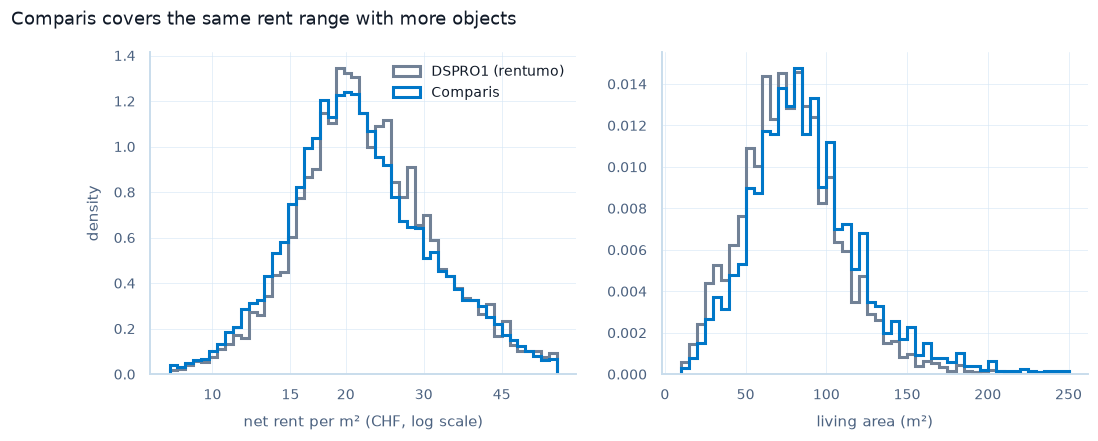

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
bins = np.linspace(np.log(8), np.log(60), 50)
for df, label, color in [
    (dspro1, "DSPRO1 (rentumo)", COLORS["gray"]),
    (market, "Comparis", COLORS["primary"]),
]:
    axes[0].hist(
        np.log(df["price"] / df["area"]),
        bins=bins,
        density=True,
        histtype="step",
        linewidth=2,
        label=label,
        color=color,
    )
    axes[1].hist(
        df["area"],
        bins=np.arange(10, 251, 5),
        density=True,
        histtype="step",
        linewidth=2,
        label=label,
        color=color,
    )
ticks = [10, 15, 20, 30, 45]
axes[0].set_xticks(np.log(ticks), ticks)
axes[0].set(xlabel="net rent per m² (CHF, log scale)", ylabel="density")
axes[1].set(xlabel="living area (m²)")
axes[0].legend(frameon=False)
fig.suptitle("Comparis covers the same rent range with more objects", x=0.01, ha="left")
plt.show()

## 12. Write `comparis_cleaned.db`

`listings.drop_reason` records why a listing is not in `rent` or `buy`: scope (section 5),
`duplicate` (a further listing of an object), `admin_unmatched` or a domain rule. `analysis` is
`rent` or `buy` for listings in scope, `object_id` is set for all of them (`obj_…` / `buy_…`).

In [16]:
drop_reason = scope.copy()
for ids, objs, removed in ((object_ids, objects, removed_domain),
                           (buy_object_ids, buy_objects, buy_removed)):
    drop_reason[ids.index[~ids.index.isin(objs.index)]] = "duplicate"
    drop_reason[objs.index[objs["admin_match"].eq("none")]] = "admin_unmatched"
    drop_reason[removed.index] = removed["reason"]
listings_out = listings.assign(object_id=pd.concat([object_ids, buy_object_ids]),
                               analysis=analysis, drop_reason=drop_reason)
assert listings_out["drop_reason"].isna().sum() == len(kept) + len(buy_kept)

steps = pd.DataFrame(
    [
        ("all", "raw listings", len(raw)),
        ("rent", "rentals with monthly price and coordinates", len(rent)),
        ("rent", "one row per object (dedup)", len(objects)),
        ("rent", "admin match in Switzerland", len(matched)),
        ("rent", "domain rules (area, rent, rooms)", len(kept)),
        ("rent", "of which market apartments without CHF/m² outlier", len(market)),
        ("buy", "flats and houses for sale with total price and coordinates", len(buy)),
        ("buy", "one row per object (dedup)", len(buy_objects)),
        ("buy", "admin match in Switzerland", len(buy_matched)),
        ("buy", "domain rules (price >= 50k, area, rooms)", len(buy_kept)),
        ("buy", "of which without CHF/m² outlier", int((~buy_kept["ppsqm_outlier"]).sum())),
    ],
    columns=["analysis", "step", "n_rows"],
)
steps["removed"] = (-steps.groupby("analysis")["n_rows"].diff()).fillna(0).astype(int)
steps["retained_pct"] = (100 * steps["n_rows"] / len(raw)).round(1)
display(steps)

all_links = pd.concat([links.assign(analysis="rent"), buy_links.assign(analysis="buy")],
                      ignore_index=True)
tables = {"listings": listings_out, "rent": kept, "buy": buy_kept,
          "duplicate_links": all_links, "cleaning_log": steps,
          "enrichment_coverage": coverage.reset_index()}
tables["meta"] = comparis.meta_table(RAW_DB, tables)
comparis.write_db(tables, CLEANED_DB)

,analysis,step,n_rows,removed,retained_pct
0,all,raw listings,65552,0,100.0
1,rent,rentals with monthly price and coordinates,25666,0,39.2
2,rent,one row per object (dedup),23129,2537,35.3
3,rent,admin match in Switzerland,23129,0,35.3
4,rent,"domain rules (area, rent, rooms)",19571,3558,29.9
5,rent,of which market apartments without CHF/m² outlier,17600,1971,26.8
6,buy,flats and houses for sale with total price and...,39667,0,60.5
7,buy,one row per object (dedup),35801,3866,54.6
8,buy,admin match in Switzerland,35801,0,54.6
9,buy,"domain rules (price >= 50k, area, rooms)",28476,7325,43.4


INFO rentml.comparis: Wrote /home/sa_linux/code/Elias-Martinelli/dspro2/data/interim/comparis_cleaned.db: {'listings': 65552, 'rent': 19571, 'buy': 28476, 'duplicate_links': 20863, 'cleaning_log': 11, 'enrichment_coverage': 2, 'meta': 11}


PosixPath('/home/sa_linux/code/Elias-Martinelli/dspro2/data/interim/comparis_cleaned.db')

In [17]:
with sqlite3.connect(f"{CLEANED_DB.as_uri()}?mode=ro", uri=True) as con:
    counts = {
        t: con.execute(f'SELECT COUNT(*) FROM "{t}"').fetchone()[0]
        for (t,) in con.execute("SELECT name FROM sqlite_master WHERE type = 'table'")
    }
    sample = pd.read_sql(
        "SELECT listing_id, canton, municipality_name, rooms, area, price, "
        "rent_regime, ppsqm_outlier FROM rent LIMIT 5",
        con,
    )
print(counts, f"| {CLEANED_DB.stat().st_size / 1e6:,.0f} MB")
display(sample)

{'listings': 65552, 'rent': 19571, 'buy': 28476, 'duplicate_links': 20863, 'cleaning_log': 11, 'enrichment_coverage': 2, 'meta': 11} | 320 MB


,listing_id,canton,municipality_name,rooms,area,price,rent_regime,ppsqm_outlier
0,16969699,GE,Collonge-Bellerive,5.0,180.0,4200.0,market,0
1,22811252,TI,Lugano,4.5,135.0,2300.0,market,0
2,28359071,TI,Chiasso,3.5,80.0,900.0,market,0
3,30590938,BL,Füllinsdorf,4.5,101.0,1760.0,market,0
4,30594243,TI,Locarno,2.5,49.0,1200.0,market,0
